# **Importing the Libraries**

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy as sp
import scipy.stats as stats
from sklearn.tree import DecisionTreeRegressor

import warnings
warnings.filterwarnings('ignore')


# **Data Loading**

In [22]:
import pandas as pd
df = pd.read_csv("/kaggle/input/datasets/shreyanshkaushik02/insurance/insurance.csv")

In [23]:
df.head()

,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86


In [24]:
df.sample(5)

,age,sex,bmi,children,smoker,region,expenses
220,34,female,33.7,1,no,southwest,5012.47
180,58,male,28.6,0,no,northwest,11735.88
335,64,male,34.5,0,no,southwest,13822.80
304,57,female,38.0,2,no,southwest,12646.21
771,53,female,26.7,2,no,southwest,11150.78


In [25]:
df.shape

(1338, 7)

# **EDA**

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   expenses  1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [27]:
df.isnull().sum() # no null values

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
expenses    0
dtype: int64

In [28]:
#getting all the statistics of numerical columns
df.describe()

,age,bmi,children,expenses
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.665471,1.094918,13270.422414
std,14.049960,6.098382,1.205493,12110.011240
min,18.000000,16.000000,0.000000,1121.870000
25%,27.000000,26.300000,0.000000,4740.287500
50%,39.000000,30.400000,1.000000,9382.030000
75%,51.000000,34.700000,2.000000,16639.915000
max,64.000000,53.100000,5.000000,63770.430000


In [29]:
df.duplicated().sum()

np.int64(1)

In [30]:
duplicates=df.duplicated()
df[duplicates]

,age,sex,bmi,children,smoker,region,expenses
581,19,male,30.6,0,no,northwest,1639.56


In [31]:
#these two rows are duplicate
duplicates_all = df[df.duplicated(keep=False)]
duplicates_all

,age,sex,bmi,children,smoker,region,expenses
195,19,male,30.6,0,no,northwest,1639.56
581,19,male,30.6,0,no,northwest,1639.56


In [32]:
df.drop_duplicates(inplace=True)

In [33]:
df.nunique()

age           47
sex            2
bmi          275
children       6
smoker         2
region         4
expenses    1337
dtype: int64

In [34]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'expenses'], dtype='object')

In [35]:
df['age'].dtype

dtype('int64')

In [36]:
df.head(1)

,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92


In [37]:
#getting the numerical feature and categorical features
num_features = [feature for feature in df.columns if df[feature].dtype!='O']
cat_features = [feature for feature in df.columns if df[feature].dtype=='O']
target = "charges"

print(f'We have {len(num_features)} number of  numerical features which are', num_features)
print(f'We have {len(cat_features)}  number of categorical featureswhich are', cat_features)

We have 4 number of  numerical features which are ['age', 'bmi', 'children', 'expenses']
We have 3  number of categorical featureswhich are ['sex', 'smoker', 'region']


In [38]:
num_data = df[num_features]
cat_data = df[cat_features]

<Axes: xlabel='bmi_range', ylabel='count'>

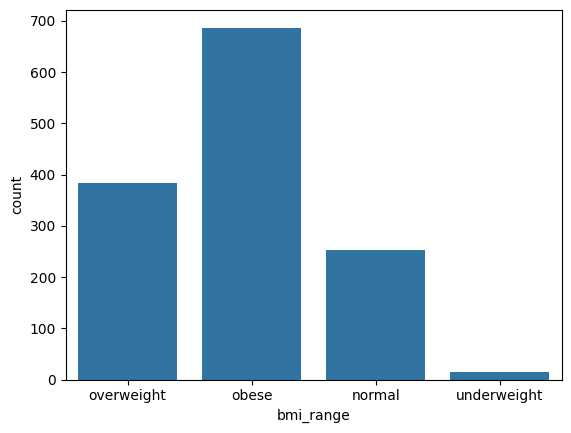

In [39]:
df['bmi_range'] = 'normal'
df.loc[(df['bmi'] < 18), 'bmi_range'] = 'underweight'
df.loc[(df['bmi'] > 25.0) & (df['bmi'] < 30), 'bmi_range'] = 'overweight'
df.loc[(df['bmi'] > 30.1), 'bmi_range'] = 'obese'
df.head()
sns.countplot(x=df['bmi_range'])

In [40]:
df.value_counts(['sex','smoker'])

sex     smoker
female  no        547
male    no        516
        yes       159
female  yes       115
Name: count, dtype: int64

In [41]:
#pivot table for sex and smoker
pd.crosstab(df['sex'],df['smoker'])

smoker,no,yes
sex,,
female,547,115
male,516,159


In [42]:
df.value_counts(['sex','bmi_range'])

sex     bmi_range  
male    obese          361
female  obese          326
        overweight     197
male    overweight     187
female  normal         132
male    normal         120
female  underweight      7
male    underweight      7
Name: count, dtype: int64

In [43]:
num_data.corr()

,age,bmi,children,expenses
age,1.000000,0.109414,0.041536,0.298308
bmi,0.109414,1.000000,0.012641,0.198637
children,0.041536,0.012641,1.000000,0.067389
expenses,0.298308,0.198637,0.067389,1.000000


# **EDA for univariate**

<Axes: xlabel='sex', ylabel='count'>

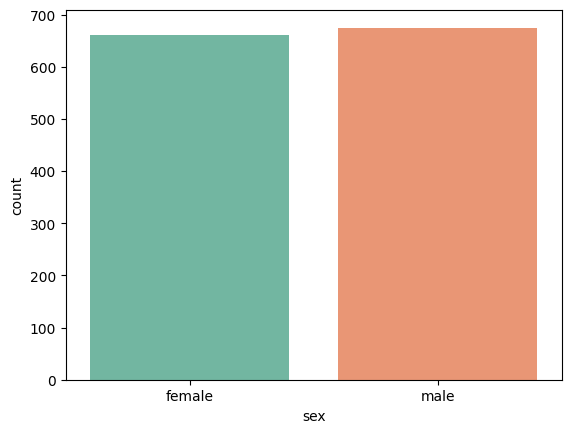

In [44]:
sns.countplot(x='sex',data=df,palette='Set2')

<Axes: xlabel='smoker', ylabel='count'>

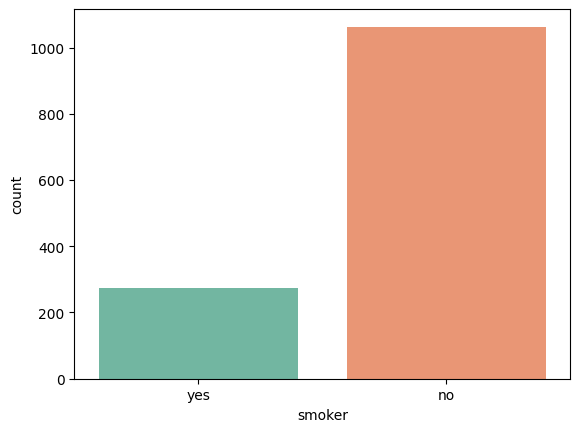

In [45]:
sns.countplot(x='smoker', data=df,palette='Set2')

<Axes: xlabel='bmi_range', ylabel='count'>

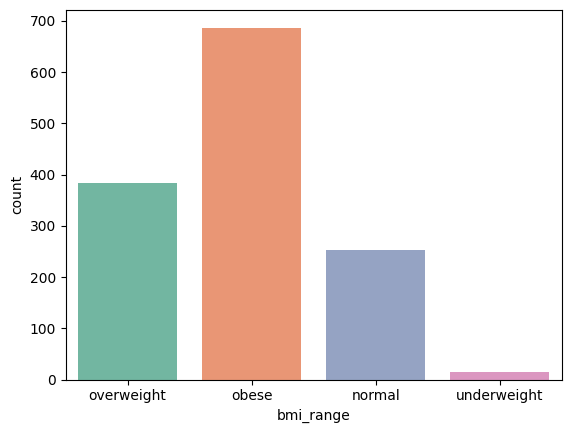

In [46]:
sns.countplot(x='bmi_range', data=df,palette='Set2')

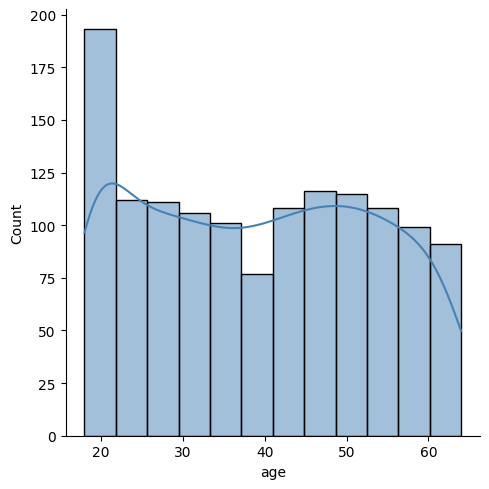

In [47]:
sns.displot(df['age'], color= ('steelblue'), kde=True)

<Axes: ylabel='age'>

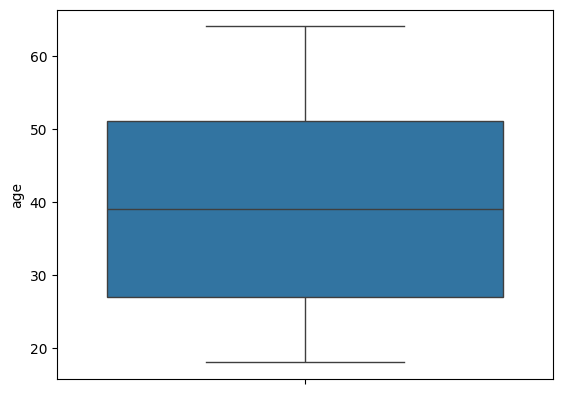

In [48]:
sns.boxplot(df['age'])

<Axes: xlabel='bmi', ylabel='Density'>

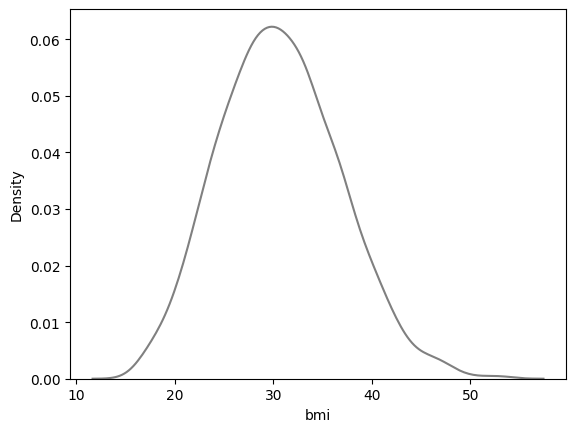

In [49]:
sns.distplot(df['bmi'], color= ('grey'), kde=True,hist=False)

<Axes: ylabel='bmi'>

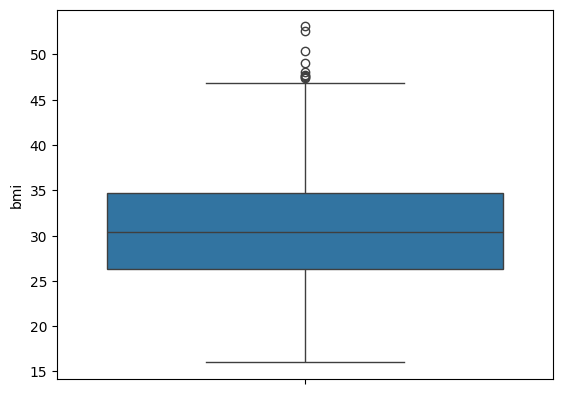

In [50]:
sns.boxplot(df['bmi'])

In [51]:
df['bmi'].skew()

np.float64(0.28446275054239506)

In [52]:
print("Mean value of bmi",df['bmi'].mean())
print("Std value of bmi",df['bmi'].std())
print("Min value of bmi",df['bmi'].min())
print("Max value of bmi",df['bmi'].max())

Mean value of bmi 30.665519820493646
Std value of bmi 6.100663828592314
Min value of bmi 16.0
Max value of bmi 53.1


In [53]:
# Finding the boundary values
print("Highest allowed",df['bmi'].mean() + 3*df['bmi'].std())
print("Lowest allowed",df['bmi'].mean() - 3*df['bmi'].std())

Highest allowed 48.96751130627059
Lowest allowed 12.363528334716705


In [54]:
#finding the z value to remove outliers
df['bmi_zscore'] = (df['bmi'] - df['bmi'].mean())/df['bmi'].std()

In [55]:
df.shape

(1337, 9)

In [56]:
# Trimming
new_df = df[(df['bmi_zscore'] < 3) & (df['bmi_zscore'] > -3)]
new_df.shape

(1333, 9)

<Axes: ylabel='bmi'>

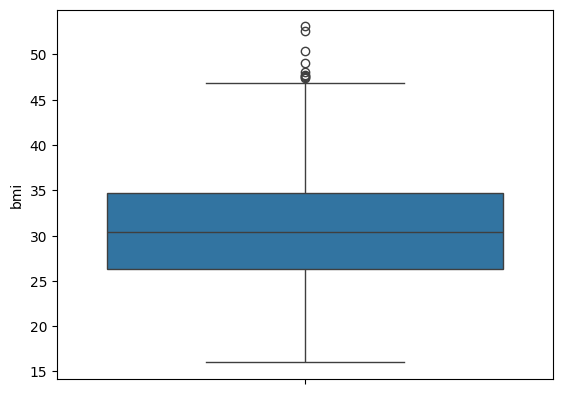

In [57]:
sns.boxplot(df['bmi'])

In [58]:
#removing outliers
Q1 = df['bmi'].quantile(0.25)
Q3 = df['bmi'].quantile(0.75)
IQR = Q3-Q1

lb = Q1 - 1.5*IQR
ub = Q3 + 1.5*IQR

df = df[(df['bmi'] >= lb) & (df['bmi'] <= ub)]
df.shape

(1328, 9)

<Axes: ylabel='bmi'>

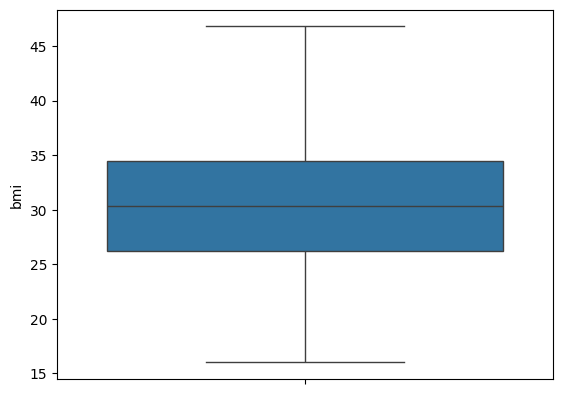

In [59]:
sns.boxplot(df['bmi'])

# **Observing the target column graph**

<Axes: xlabel='expenses', ylabel='Density'>

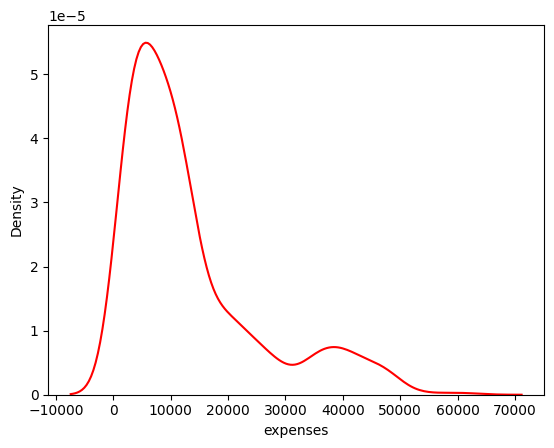

In [60]:
sns.distplot(df['expenses'], color= ('red'), kde=True,hist=False)

# **Bivariate Analysis**

<Axes: xlabel='sex', ylabel='expenses'>

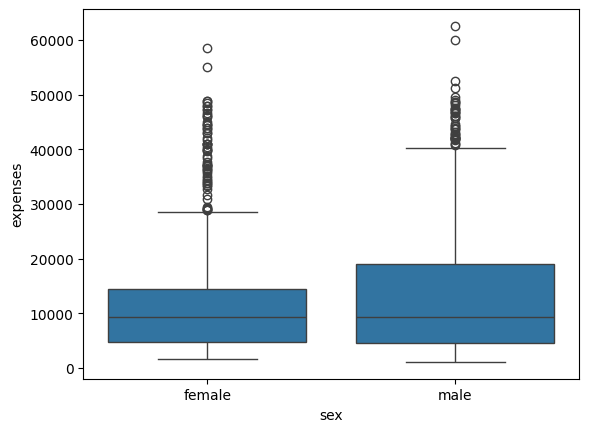

In [61]:
sns.boxplot(df, x='sex', y = 'expenses')

<Axes: xlabel='children', ylabel='expenses'>

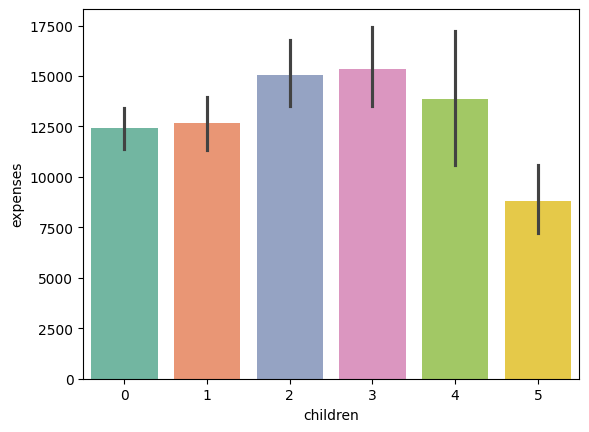

In [62]:
sns.barplot(new_df, x = 'children', y = 'expenses',palette='Set2')

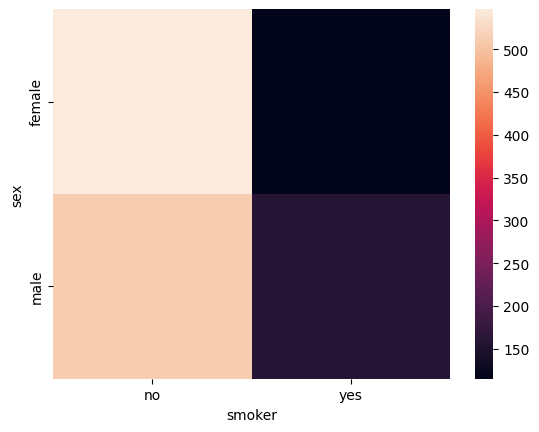

In [63]:
sns.heatmap(pd.crosstab(new_df['sex'],new_df['smoker']))
plt.show()

<Axes: xlabel='smoker', ylabel='expenses'>

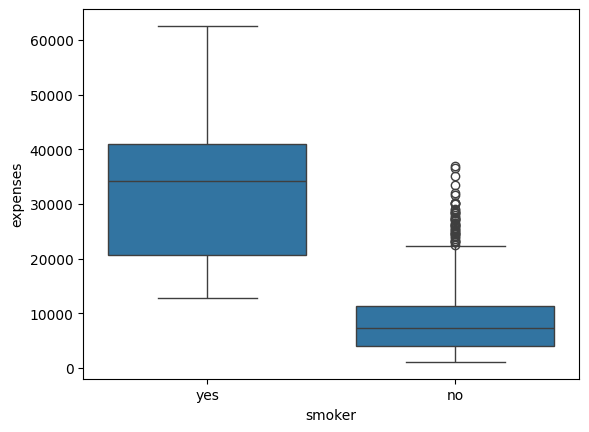

In [64]:
sns.boxplot(df, x='smoker', y = 'expenses')

In [65]:
pd.crosstab(df['bmi_range'],df['smoker'])

smoker,no,yes
bmi_range,,
normal,198,54
obese,538,140
overweight,310,74
underweight,11,3


In [66]:
#observing normal obese overweight according to smoking havint and age
new_df.loc[(new_df['age'] > 45), 'overage'] = 'yes'
new_df.loc[(new_df['age'] <= 45), 'overage'] = 'no'
pd.crosstab(index=[new_df['overage'], new_df['smoker']], columns=new_df['bmi_range'],values=new_df['expenses'],aggfunc='mean' )

bmi_range             normal         obese    overweight  underweight
overage smoker                                                       
no      no       5806.167704   5846.241242   5797.392886      3510.95
        yes     18831.797000  39243.883111  20498.932500     20006.43
yes     no      12303.504286  12831.940638  12753.518532          NaN
        yes     23808.621429  46038.579423  26182.535385          NaN

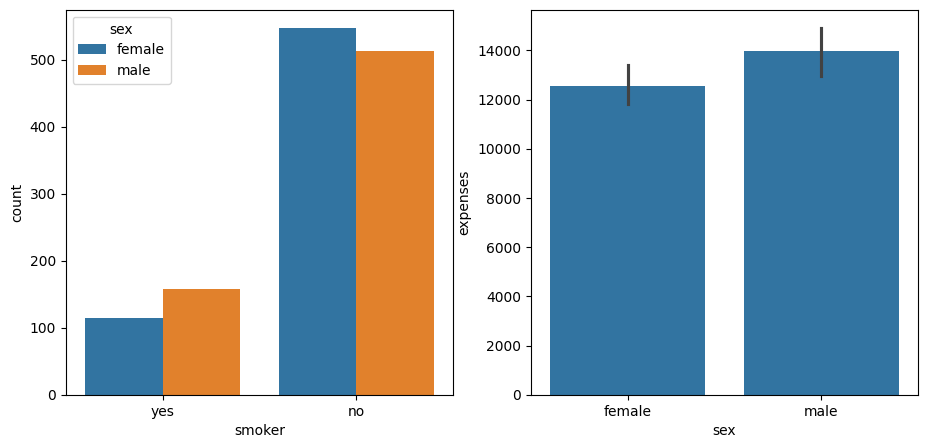

In [67]:
fig, ax = plt.subplots(1,2,figsize=(11,5))

sns.countplot(data=new_df, x=new_df['smoker'], hue=new_df['sex'], ax=ax[0])
sns.barplot(new_df, x = 'sex', y = 'expenses', ax = ax[1])
fig.show()

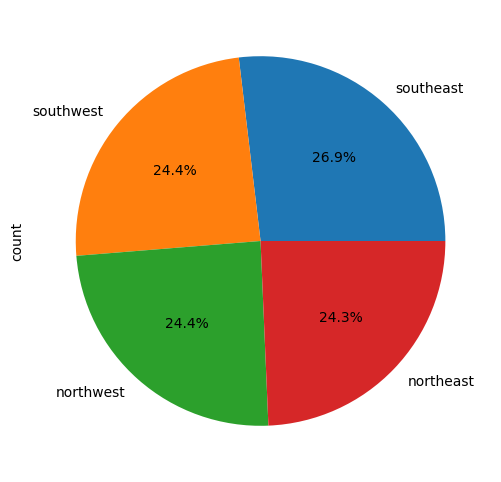

In [68]:
df['region'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(6,6))
plt.show()

expenses    1.000000
age         0.298308
bmi         0.198637
children    0.067389
Name: expenses, dtype: float64 



<Axes: >

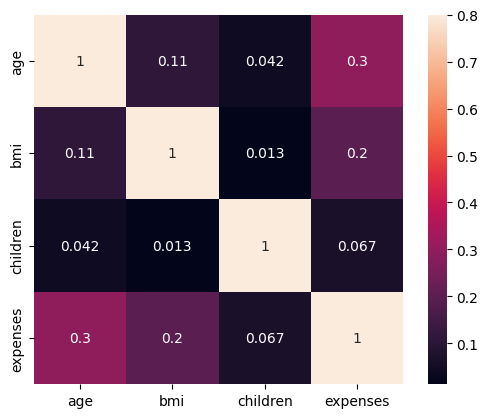

In [69]:
correlation = num_data.corr()
print(correlation['expenses'].sort_values(ascending=False),'\n')
sns.heatmap(correlation, square=True, vmax=0.8, annot=True)

<Axes: xlabel='region', ylabel='expenses'>

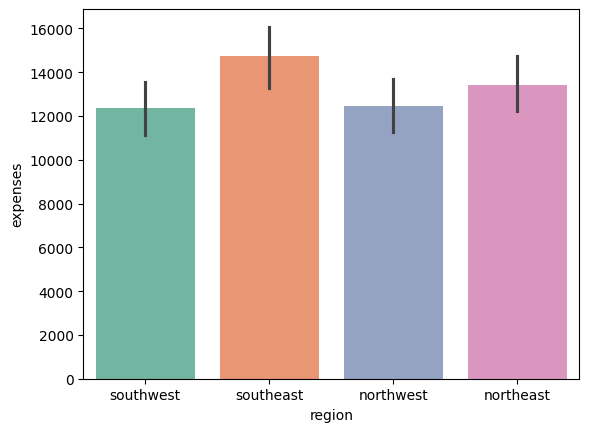

In [70]:
#making barplot for expenses and region
sns.barplot(new_df, x = 'region', y = 'expenses',palette='Set2')

In [71]:
new_df.head() # we have dropped the added columns which were bmi_range and bmi_zscore

,age,sex,bmi,children,smoker,region,expenses,bmi_range,bmi_zscore,overage
0,19,female,27.9,0,yes,southwest,16884.92,overweight,-0.453315,no
1,18,male,33.8,1,no,southeast,1725.55,obese,0.513793,no
2,28,male,33.0,3,no,southeast,4449.46,obese,0.382660,no
3,33,male,22.7,0,no,northwest,21984.47,normal,-1.305681,no
4,32,male,28.9,0,no,northwest,3866.86,overweight,-0.289398,no


# **PreProcessing**

**One Hot Encoding**

In [72]:
#one hot encoding
cat_data = pd.get_dummies(cat_data, drop_first=True,dtype=np.int32)
cat_data.head()

,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,0,1,0,0,1
1,1,0,0,1,0
2,1,0,0,1,0
3,1,0,1,0,0
4,1,0,1,0,0


In [73]:
#adding above dataframe with num_data
df = pd.concat([num_data, cat_data], axis=1)
df.head()

,age,bmi,children,expenses,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.9,0,16884.92,0,1,0,0,1
1,18,33.8,1,1725.55,1,0,0,1,0
2,28,33.0,3,4449.46,1,0,0,1,0
3,33,22.7,0,21984.47,1,0,1,0,0
4,32,28.9,0,3866.86,1,0,1,0,0


**Scaling**

In [74]:
X = df.drop('expenses', axis=1)
y = df['expenses']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [75]:
#scaling
scaler = StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [76]:
X_train_scaled = pd.DataFrame(X_train, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test, columns=X.columns)

In [77]:
X_train_scaled.shape[1]

8

In [78]:
X = sm.add_constant(X)
model = sm.OLS(y,X).fit()

In [79]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               expenses   R-squared:                       0.751
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     500.0
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:40:25   Log-Likelihood:                -13538.
No. Observations:                1337   AIC:                         2.709e+04
Df Residuals:                    1328   BIC:                         2.714e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.194e+04    988.219    -12.082      0.000   -1.39e+04      -1e+04
age                256.7472     11.912     21.554      0.000     233.379     280.116
bmi                339.3472     28.610     11.861      0.000     283.221     395.473
children           475.0071    137.892      3.445      0.001     204.496     745.518
sex_male          -129.5144    333.185     -0.389      0.698    -783.140     524.111
smoker_yes        2.385e+04    413.334     57.693      0.000     2.3e+04    2.47e+04
region_northwest  -349.0429    476.809     -0.732      0.464   -1284.424     586.338
region_southeast -1035.8409    478.855     -2.163      0.031   -1975.236     -96.445
region_southwest  -959.3365    478.085     -2.007      0.045   -1897.220     -21.453
==============================================================================
Omnibus:                      299.949   Durbin-Watson:                   2.089
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              717.046
Skew:                           1.211   Prob(JB):                    1.97e-156
Kurtosis:                       5.647   Cond. No.                         311.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**INFLUENTIAL POINTS**

In [80]:
influence = model.get_influence()
cooks = influence.cooks_distance
print(cooks)

(array([2.03461470e-03, 5.05434475e-05, 9.78389275e-05, ...,
       1.28217008e-04, 1.08425111e-05, 1.91730530e-03]), array([1., 1., 1., ..., 1., 1., 1.]))


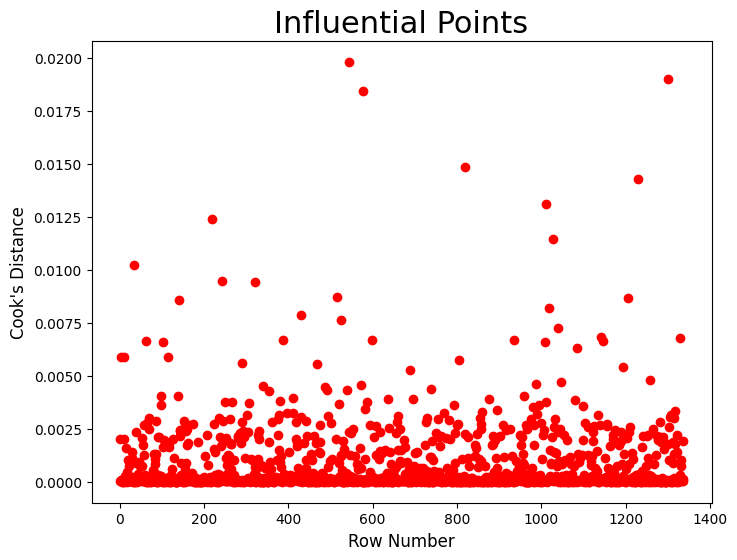

In [81]:
plt.figure(figsize = (8,6))
plt.scatter(df.index, cooks[0], color='red')
plt.xlabel('Row Number', fontsize=12)
plt.ylabel("Cook's Distance", fontsize=12)
plt.title("Influential Points", fontsize=22)
plt.show()

In [82]:
mean_cooks = np.mean(cooks[0])
mean_cooks

np.float64(0.0008419517504815391)

In [83]:
influential_points = df.index[cooks[0] > (4/1338)]
influential_points

Index([   3,    9,   34,   62,   98,   99,  102,  115,  138,  140,  219,  235,
        242,  250,  266,  289,  301,  306,  321,  340,  355,  379,  380,  387,
        397,  411,  412,  429,  430,  468,  488,  491,  494,  516,  520,  526,
        539,  543,  573,  577,  583,  587,  599,  637,  661,  688,  696,  730,
        739,  770,  793,  806,  819,  854,  860,  876,  896,  936,  959,  980,
        987,  989,  994, 1008, 1011, 1012, 1019, 1027, 1039, 1047, 1080, 1085,
       1100, 1134, 1142, 1146, 1195, 1206, 1230, 1258, 1300, 1306, 1307, 1314,
       1317, 1328],
      dtype='int64')

In [84]:
df.iloc[influential_points, :]

,age,bmi,children,expenses,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
3,33,22.7,0,21984.47,1,0,1,0,0
9,60,25.8,0,28923.14,0,0,1,0,0
34,28,36.4,1,51194.56,1,1,0,0,1
62,64,24.7,1,30166.62,1,0,1,0,0
98,56,20.0,0,22412.65,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...
1307,32,28.1,4,21472.48,1,1,1,0,0
1308,25,30.2,0,33900.65,0,1,0,0,1
1315,18,28.3,1,11272.33,1,0,0,0,0
1318,35,39.7,4,19496.72,1,0,0,0,0


In [85]:
df = df.drop(influential_points)
df.head()

,age,bmi,children,expenses,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.9,0,16884.92,0,1,0,0,1
1,18,33.8,1,1725.55,1,0,0,1,0
2,28,33.0,3,4449.46,1,0,0,1,0
4,32,28.9,0,3866.86,1,0,1,0,0
5,31,25.7,0,3756.62,0,0,0,1,0


# **Fitting the MLR Model**

In [86]:
X = df.drop(columns = 'expenses', axis=1)
Y = df['expenses']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [87]:
#scaling
scaler = StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [88]:
X_train_scaled = pd.DataFrame(X_train, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test, columns=X.columns)

In [89]:
X_train_scaled.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,0.022635,1.720993,-0.069307,0.990050,-0.481173,-0.560411,-0.597371,-0.594289
1,-0.691399,2.037717,0.755776,-1.010051,-0.481173,-0.560411,1.674002,-0.594289
2,-1.548239,0.404089,-0.894389,0.990050,-0.481173,-0.560411,1.674002,-0.594289
3,0.522458,2.771182,-0.069307,0.990050,-0.481173,-0.560411,1.674002,-0.594289
4,1.093685,0.720813,-0.069307,0.990050,-0.481173,-0.560411,-0.597371,-0.594289


In [90]:
lr = LinearRegression()
model = lr.fit(X_train, Y_train)

In [91]:
Y_train_pred = model.predict(X_train)
Y_test_pred = model.predict(X_test)

In [92]:
print(model.intercept_)

12374.355019999999


In [93]:
print("Training R^2 = ",r2_score(Y_train, Y_train_pred))
print("Testing R^2 = ",r2_score(Y_test, Y_test_pred))

Training R^2 =  0.8496520330979158
Testing R^2 =  0.8380581288698353


In [94]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
X = df.drop('expenses', axis=1)
y = df['expenses']

# Split and scale
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# OLS model
import statsmodels.api as sm
X_with_const = sm.add_constant(X_train_scaled)
ols_model = sm.OLS(y_train, X_with_const).fit()
ols_coefs = pd.Series(ols_model.params.values, index=ols_model.params.index)

# 1. Linearity

**1. Assumption**

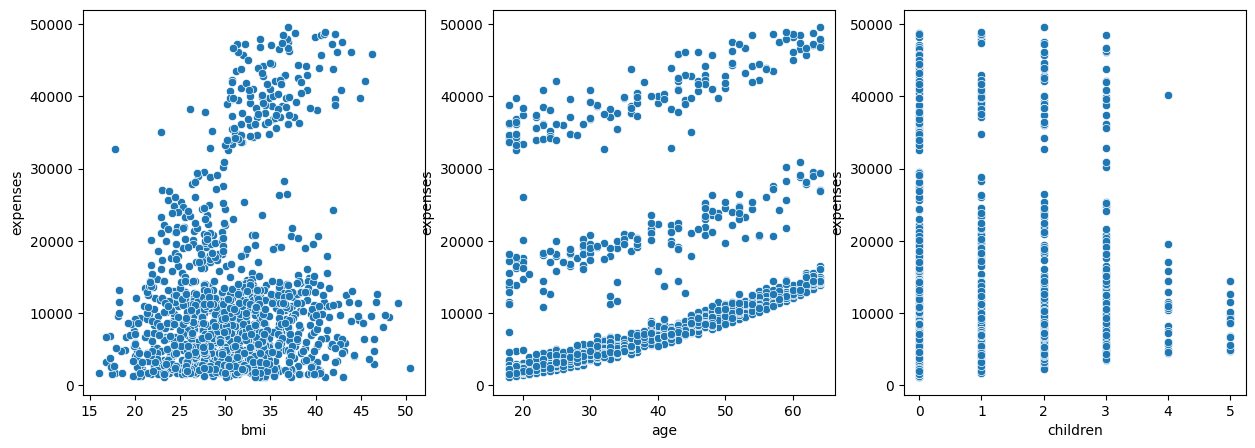

In [95]:
#to draw a subplot for bmi,age, children with expenses

fig,(ax1,ax2,ax3)=plt.subplots(1,3,figsize=(15,5))
sns.scatterplot(x=df['bmi'], y=df['expenses'],ax=ax1)
sns.scatterplot(x=df['age'], y=df['expenses'],ax=ax2)
sns.scatterplot(x=df['children'], y=df['expenses'],ax=ax3)
plt.show()

**2. Normality Of residuals**

In [96]:
residual=Y_test-Y_test_pred

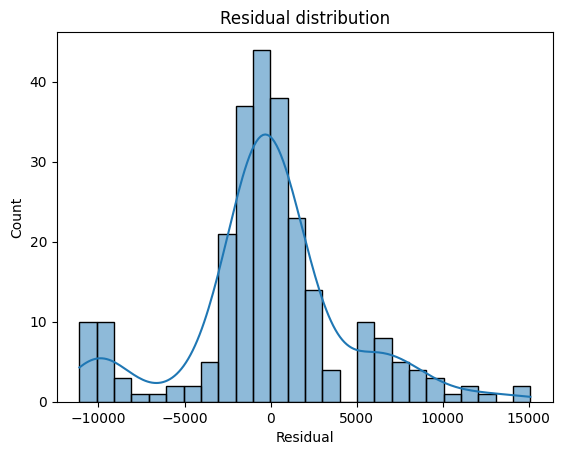

In [97]:
sns.histplot(residual, kde=True)
plt.xlabel("Residual")
plt.title("Residual distribution")
plt.show()

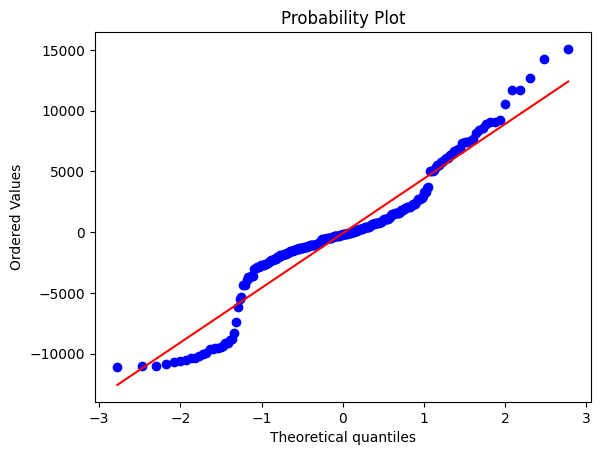

In [98]:
#QQ plot
stats.probplot(residual, dist="norm", plot=plt)
plt.show()

In [99]:
#shapiro-wilk test
statistic, p_value = sp.stats.shapiro(residual)
print("Statistic :", statistic)
print("p value :", p_value)

Statistic : 0.9284795295966688
p value : 1.1731423732140007e-09


**3. Homoscedasticity**

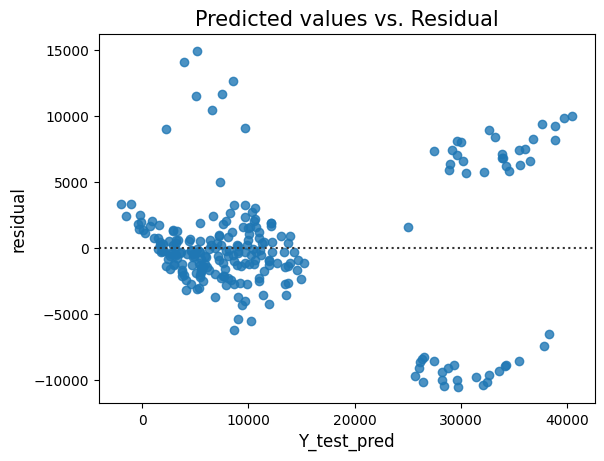

In [100]:
sns.residplot(x=Y_test_pred, y=residual)
plt.xlabel("Y_test_pred", fontsize = 12)
plt.ylabel("residual", fontsize = 12)
plt.title("Predicted values vs. Residual", fontsize=15)
plt.show()

As from the above figure we can that we cant find any pattern of data between the residuals and Y_test_pred , therefore it is homoscedastic.

**4. Multicollinearity **

In [101]:
#VIF
vif = pd.DataFrame()
vif["VIF Factor"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif["features"] = X.columns
vif

,VIF Factor,features
0,1.019899,age
1,1.119239,bmi
2,1.005738,children
3,1.011510,sex_male
4,1.014455,smoker_yes
5,1.527417,region_northwest
6,1.667116,region_southeast
7,1.540956,region_southwest


VIF of 'age' feature is greater than 5 indicating possible existence of multicollinearity. VIF of 'bmi' feature is greater that 10 indicating presence of significant multicollinearity that needs to be corrected.

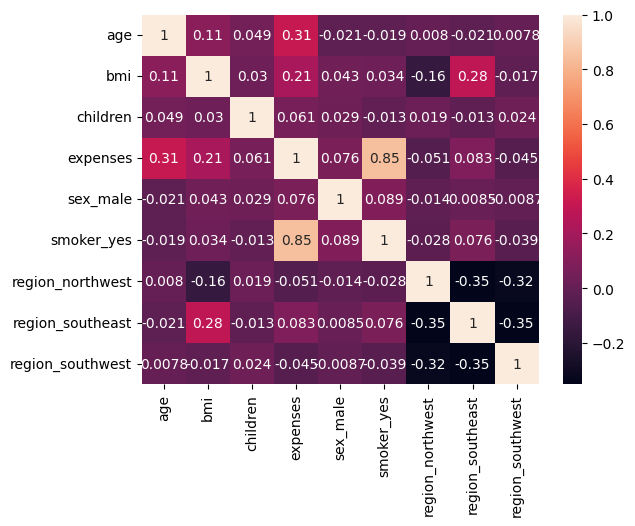

In [102]:
# CORRELATION HEATMAP
sns.heatmap(df.corr(), annot=True)
plt.show()

But after drawing the heatmap we can see there does not exist high collinearity between any two columns of the data therefore multicollinearity also does not exist

In [103]:
4630#standard deviation of residual
np.std(residual)

4630.307880099525

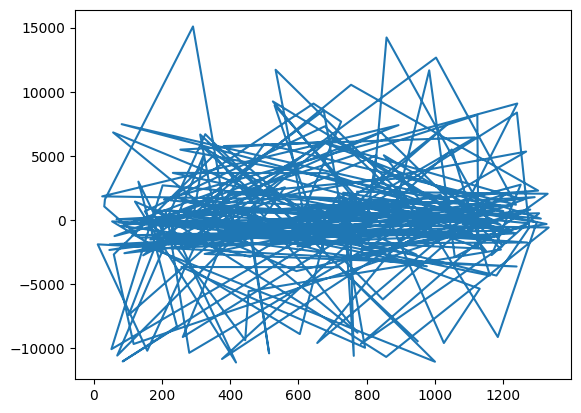

In [104]:
plt.plot(residual)

From the plot also we can say that there is no Autocorrelation

# **Applying all other models**

In [105]:
def evaluate_model(true, predicted, n, p):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(true, predicted)
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return mae, mse, r2, rmse, adjusted_r2

In [106]:
models = {

    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Decision Tree": DecisionTreeRegressor(),
}
model_list = []
r2_list = []
adjusted_r2_list = []
cv_scores = []

for i in range(len(list(models))):
    model = list(models.values())[i]

    # Training
    model.fit(X_train, Y_train)

    # Predictions
    Y_train_pred= model.predict(X_train)
    Y_test_pred = model.predict(X_test)

    # Evaluations
    n_train, p_train = X_train.shape
    n_test, p_test = X_test.shape
    model_train_mae, model_train_mse, model_train_r2, model_train_rmse, model_train_adj_r2 = evaluate_model(Y_train, Y_train_pred, n_train, p_train)
    model_test_mae, model_test_mse, model_test_r2, model_test_rmse, model_test_adj_r2 = evaluate_model(Y_test, Y_test_pred, n_test, p_test)

    # Cross-validation score
    cv_score = cross_val_score(model, X, Y, cv=5, scoring='r2').mean()
    cv_scores.append(cv_score)

    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])

    print('Model performance for Training set')
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))
    print("- Adjusted R2 Score: {:.4f}".format(model_train_adj_r2))

    print('----------------------------------')

    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))
    print("- Adjusted R2 Score: {:.4f}".format(model_test_adj_r2))
    print("- Cross-validation Score: {:.4f}".format(cv_score))

    r2_list.append(model_test_r2)
    adjusted_r2_list.append(model_test_adj_r2)
    cv_scores.append(cv_score)
    print('='*35)
    print('\n')

Linear Regression
Model performance for Training set
- Root Mean Squared Error: 4459.4269
- Mean Absolute Error: 3048.2363
- R2 Score: 0.8497
- Adjusted R2 Score: 0.8484
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 4631.2042
- Mean Absolute Error: 3124.0818
- R2 Score: 0.8381
- Adjusted R2 Score: 0.8327
- Cross-validation Score: 0.8448


Ridge
Model performance for Training set
- Root Mean Squared Error: 4459.8936
- Mean Absolute Error: 3056.9828
- R2 Score: 0.8496
- Adjusted R2 Score: 0.8484
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 4624.3680
- Mean Absolute Error: 3130.4807
- R2 Score: 0.8385
- Adjusted R2 Score: 0.8332
- Cross-validation Score: 0.8447


Decision Tree
Model performance for Training set
- Root Mean Squared Error: 279.5358
- Mean Absolute Error: 12.5012
- R2 Score: 0.9994
- Adjusted R2 Score: 0.9994
----------------------------------
Model performance for Test set
- Root 

In [107]:
pd.DataFrame(
    list(zip(model_list, r2_list, adjusted_r2_list)),
    columns=['Model Name', 'R2 Score', 'Adjusted R2']
).sort_values(by=['R2 Score'], ascending=False)

,Model Name,R2 Score,Adjusted R2
2,Decision Tree,0.873505,0.869324
1,Ridge,0.838536,0.833198
0,Linear Regression,0.838058,0.832705
